# Retry — recovering from a transient error

[Open Colab](https://colab.research.google.com/) and choose **File → Upload notebook** to open this English copy.

**Audience** — Developers new to agents who are familiar with Python functions and async/await.

**Learning objective** — Configure a retry policy and backoff, then observe when the call succeeds or propagates an error.

**Sequence** — Set up the environment, define inputs and agents, run the workflow, check the results, then try an exercise.

[Source code](../src/main.py) · [Example guide](../README.md) · [Environment setup](../../../../../docs/setup.md)

### Pattern architecture

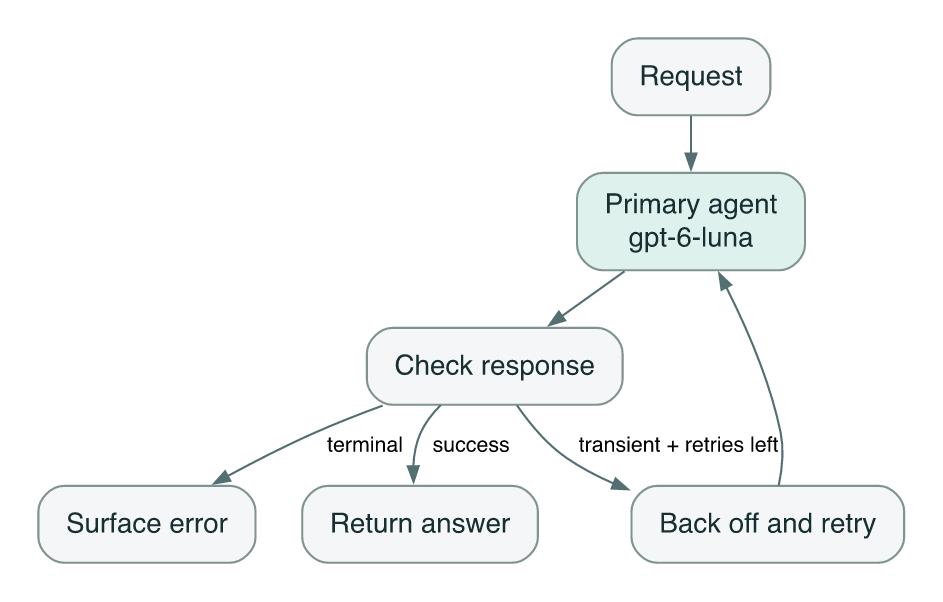

### From diagram to code

| Diagram element | Implementation | Role |
| --- | --- | --- |
| User Query | Input to `Runner.run(agent, ...)` | Request sent to the agent |
| Primary | `agent` | Primary agent that handles the request |
| Retry policy | `ModelRetrySettings` and `retry_policies` | Define eligible errors and retry limits |
| Failure | First mock response, HTTP 429 | Simulates a transient error |
| Success Output | Second mock response, HTTP 200 | Successful result after retry |
| Backup | Outside the example | Fallback to another model or agent |

#### Execution flow

1. Set the retry limit and backoff policy in `ModelRetrySettings`.
2. The local mock transport returns HTTP 429 for the first request.
3. The SDK retries the same model request according to the policy.
4. The second response succeeds and the run returns the result.

#### How the example implements the diagram

This notebook implements **retry** for transient errors. The backup path shown in the diagram would require catching the error after retries fail and branching to a separate agent or model.

## 1. Set up the environment

### Colab

1. In Colab, choose **File → Upload notebook** and select this `.ipynb` file. A CPU runtime is sufficient. You can run it without cloning the repository or mounting Google Drive.
2. The setup cell installs `openai-agents==0.22.1` and `python-dotenv` if needed. If you already imported a different SDK version, restart the runtime and run from the top.
3. For live calls, open **Secrets** (the key icon in the left sidebar), add your existing key as `OPENAI_API_KEY`, and enable access for this notebook. Keep keys out of code cells. Your local `.env.local` file is not copied into Colab.

### Local Jupyter

Install the shared notebook environment with `uv` and select its kernel. Existing environment variables take precedence. If a `.env.local` file exists in the current directory or a parent, the notebook reads additional settings from it. Offline exercises require neither the file nor a key.

### Run settings

The default `RUN_API=False` builds the agents and runs offline exercises without reading Secrets or calling the API. To see live results, set `RUN_API=True` in the next cell and run the following cells in order. Key lookup order is **environment → optional `.env.local` → Colab Secrets**. The notebook never prints or saves key values. Model calls and web searches may incur charges. Jupyter supports top-level `await` in its existing event loop.

The standalone example later in the notebook has its own `run_api=True` argument, independent of `RUN_API`.


In [ ]:
import os
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

# Install only in Colab. Local environments use requirements-notebooks.txt.
try:
    import google.colab
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    try:
        dependencies_ready = (
            version("openai-agents") == "0.22.1"
            and version("python-dotenv").split(".")[0] == "1"
        )
    except PackageNotFoundError:
        dependencies_ready = False
    if not dependencies_ready:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "--quiet",
            "openai-agents==0.22.1", "python-dotenv>=1,<2",
        ])

from agents import Agent, Runner, set_tracing_disabled
from dotenv import find_dotenv, load_dotenv


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


RUN_API = False  # Set True for the walkthrough's API and web search calls.
MODEL = load_environment(run_api=RUN_API)
set_tracing_disabled(True)
print({"environment": "Colab" if IN_COLAB else "local", "model": MODEL, "api_enabled": RUN_API})


## 2. Configure the SDK retry policy

Retry only transient HTTP statuses and network errors. Two retries allow up to three attempts including the initial call.

In [ ]:
from agents import ModelRetrySettings, ModelSettings, retry_policies

retry = ModelRetrySettings(
    max_retries=2,
    backoff={
        "initial_delay": 0.1,
        "max_delay": 1.0,
        "multiplier": 2.0,
        "jitter": False,
    },
    policy=retry_policies.any(
        retry_policies.provider_suggested(),
        retry_policies.network_error(),
        retry_policies.http_status([408, 409, 429, 500, 502, 503, 504]),
    ),
)

agent = Agent(
    name="Resilient assistant",
    model=MODEL,
    instructions="Explain the answer in at most three short bullet points.",
    model_settings=ModelSettings(retry=retry),
)

## 3. Reproduce HTTP 429 followed by success locally

The mock HTTP transport returns 429 only for the first request. Disabling the OpenAI client's built-in retries lets you observe retries driven by the SDK policy without calling the API.

In [ ]:
import httpx
from agents import OpenAIResponsesModel
from openai import AsyncOpenAI

attempts = 0


async def mock_response(request):
    global attempts
    attempts += 1

    if attempts == 1:
        return httpx.Response(
            429,
            json={
                "error": {"message": "Simulated rate limit", "type": "rate_limit_error"}
            },
        )

    return httpx.Response(
        200,
        json={
            "id": "resp_test",
            "object": "response",
            "created_at": 0,
            "model": MODEL,
            "status": "completed",
            "output": [
                {
                    "type": "message",
                    "id": "msg_test",
                    "role": "assistant",
                    "status": "completed",
                    "content": [
                        {
                            "type": "output_text",
                            "text": "Retry succeeded.",
                            "annotations": [],
                        }
                    ],
                }
            ],
            "usage": {"input_tokens": 1, "output_tokens": 1, "total_tokens": 2},
        },
    )


async with AsyncOpenAI(
    api_key="local-test-only",
    base_url="https://mock.invalid/v1",
    max_retries=0,
    http_client=httpx.AsyncClient(transport=httpx.MockTransport(mock_response)),
) as client:
    simulated = agent.clone(
        model=OpenAIResponsesModel(model=MODEL, openai_client=client)
    )
    simulated_result = await Runner.run(simulated, "Test retry", max_turns=2)

assert attempts == 2, f"Expected 2 attempts, got {attempts}"
assert simulated_result.final_output == "Retry succeeded."

print({"attempts": attempts, "result": simulated_result.final_output})

## 4. Run the live model (API call)

A successful first call produces no retry logs. The local reproduction above exercises the error path.

In [ ]:
if RUN_API:
    result = await Runner.run(
        agent,
        "Explain exponential backoff in plain English.",
        max_turns=2,
    )

    assert str(result.final_output).strip()

    print(result.final_output)
else:
    print("Real API call skipped; the local HTTP 429 test is complete.")

## 5. Run the workflow as a Python module with `main()`

The preceding cells walk through the workflow step by step. The next cell packages the same workflow as an independent Python module. Once the dependencies are installed, you can start with this cell because it defines its own agents and variables.

Build an agent with a retry policy and a function to run it. `main()` handles settings and output. The SDK retries individual model requests. The workflow has no branch to a fallback model.

| Component | Responsibility |
| --- | --- |
| `build_retry_settings()` | Defines retryable errors, limits, and backoff |
| `build_retry_agent()` | Builds the agent with its retry policy |
| `run_with_retry()` | Runs the agent and returns the final response |
| `demonstrate_local_retry()` | Simulates a 429 followed by success using a mock transport |
| `main()` | Loads settings, runs local checks, optionally calls the live API, and prints the result |

The definition cell makes no API calls. By default `main()` runs only the local demonstration. With `run_api=True` it also makes a billable API call. A limit of two retries allows at most three attempts in total.


In [ ]:
import asyncio
import os

import httpx
from agents import (
    Agent,
    ModelRetrySettings,
    ModelSettings,
    OpenAIResponsesModel,
    Runner,
    retry_policies,
    set_tracing_disabled,
)
from dotenv import find_dotenv, load_dotenv
from openai import AsyncOpenAI


def build_retry_settings() -> ModelRetrySettings:
    """Retry transient failures at most twice after the initial attempt."""
    return ModelRetrySettings(
        max_retries=2,
        backoff={
            "initial_delay": 0.1,
            "max_delay": 1.0,
            "multiplier": 2.0,
            "jitter": False,
        },
        policy=retry_policies.any(
            retry_policies.provider_suggested(),
            retry_policies.network_error(),
            retry_policies.http_status([408, 409, 429, 500, 502, 503, 504]),
        ),
    )


def build_retry_agent(model: str | OpenAIResponsesModel) -> Agent:
    """Configure an agent with the SDK retry policy."""
    return Agent(
        name="Resilient assistant",
        model=model,
        instructions="Explain the answer in at most three short bullet points.",
        model_settings=ModelSettings(retry=build_retry_settings()),
    )


async def run_with_retry(
    question: str,
    *,
    model: str | OpenAIResponsesModel,
) -> str:
    """Run one agent request; let the SDK handle retries and propagate failures."""
    agent = build_retry_agent(model)
    result = await Runner.run(agent, question, max_turns=2)

    return str(result.final_output)


async def demonstrate_local_retry(model: str) -> dict:
    """Reproduce HTTP 429 followed by success without network requests."""
    attempts = 0

    async def mock_response(request):
        nonlocal attempts
        attempts += 1

        if attempts == 1:
            return httpx.Response(
                429,
                json={
                    "error": {"message": "Simulated rate limit", "type": "rate_limit_error"}
                },
            )

        return httpx.Response(
            200,
            json={
                "id": "resp_test",
                "object": "response",
                "created_at": 0,
                "model": model,
                "status": "completed",
                "output": [
                    {
                        "type": "message",
                        "id": "msg_test",
                        "role": "assistant",
                        "status": "completed",
                        "content": [
                            {
                                "type": "output_text",
                                "text": "Retry succeeded.",
                                "annotations": [],
                            }
                        ],
                    }
                ],
                "usage": {"input_tokens": 1, "output_tokens": 1, "total_tokens": 2},
            },
        )

    async with AsyncOpenAI(
        api_key="local-test-only",
        base_url="https://mock.invalid/v1",
        max_retries=0,  # Test the SDK policy without client-level retries.
        http_client=httpx.AsyncClient(
            transport=httpx.MockTransport(mock_response)
        ),
    ) as client:
        output = await run_with_retry(
            "Test retry",
            model=OpenAIResponsesModel(model=model, openai_client=client),
        )

    assert attempts == 2, f"Expected 2 attempts, got {attempts}"
    assert output == "Retry succeeded."

    return {"attempts": attempts, "output": output}


def load_environment(*, run_api: bool) -> str:
    """Load optional local settings; request Colab Secrets only for live runs."""
    env_path = find_dotenv(filename=".env.local", usecwd=True)
    if env_path:
        load_dotenv(env_path, override=False)

    if run_api and not os.getenv("OPENAI_API_KEY", "").strip():
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError(
                "Set OPENAI_API_KEY in your environment or .env.local before enabling API calls."
            ) from None

        try:
            key = userdata.get("OPENAI_API_KEY")
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
            raise RuntimeError(
                "In Colab Secrets, add OPENAI_API_KEY and enable Notebook access, "
                "then rerun this cell."
            ) from None
        if not isinstance(key, str) or not key.strip():
            raise RuntimeError("The OPENAI_API_KEY secret is empty.")
        os.environ["OPENAI_API_KEY"] = key.strip()

    return os.getenv("AGENT_MODEL", "gpt-6-luna")


async def main(
    question: str = "Explain exponential backoff in plain English.",
    *,
    run_api: bool = False,
) -> dict:
    """Load configuration, demonstrate retries locally, and optionally call the API."""
    model = load_environment(run_api=run_api)
    set_tracing_disabled(True)

    local_result = await demonstrate_local_retry(model)
    print("Local retry test:", local_result)

    result = {"local_test": local_result, "api_output": None}

    if not run_api:
        print("Real API call skipped. Pass run_api=True to enable it.")
        return result

    result["api_output"] = await run_with_retry(question, model=model)
    print(result["api_output"])

    return result


### Calling the workflow in a notebook

Use `await main(...)` in Jupyter. The next cell runs the local 429 scenario and skips the live call. The example looks for `.env.local` in the current directory or its parents. The local reproduction requires no real API key.

Set `run_api=True` to also call the live model. This starts a fresh run independent of the earlier exercise.


In [ ]:
standalone_result = await main(
    question="Explain exponential backoff in plain English.",
    run_api=False,  # Run the local test only; set True to also call the API.
)


### Running `retry_agent.py`

1. Copy the **entire function definition cell** into `retry_agent.py`. Leave the notebook-only `await main(...)` invocation in the notebook.

2. Add the following entry point at the bottom of the file. Live calls run only when you pass `--run-api`.

   ```python
   if __name__ == "__main__":
       import argparse

       parser = argparse.ArgumentParser(description="Demonstrate agent retries.")
       parser.add_argument("--run-api", action="store_true")
       args = parser.parse_args()

       asyncio.run(main(run_api=args.run_api))
   ```

3. Activate the virtual environment containing the exercise dependencies and run the commands below. For live calls, set `OPENAI_API_KEY` in the environment or the optional `.env.local` file.

   ```bash
   python retry_agent.py            # Run only the local HTTP 429 reproduction
   python retry_agent.py --run-api  # Run the workflow; API costs apply
   ```

In another module, use `from retry_agent import run_with_retry` and call `await run_with_retry(question, model=...)`. The caller supplies environment variables and tracing settings. The `if __name__ == "__main__":` guard prevents execution on import.

The local demo initializes `attempts` to zero on each invocation. It disables the OpenAI client's retries so you can observe the SDK policy. If the first live request succeeds, no retry is needed. Ineligible errors and errors that exhaust the retry limit propagate to the caller. The workflow has no backup agent or model.

This standalone example is separate from `src/main.py`. When distributing it, retain the notebook attribution and the repository's `THIRD_PARTY_NOTICES.md`.


## Try it yourself

Change the first local response to HTTP 400. Check that the run fails without retrying, then restore HTTP 429.

## Changes from upstream and limitations

This version simplifies the policy and adds a mock transport. It retries individual requests and has no backup model. Workflows with side-effecting tools need a separate design to prevent duplicate actions.

## Sources

- [Local source](../src/main.py)
- [Official OpenAI example](https://github.com/openai/openai-agents-python/blob/25af629b3c877ba3d0e95189141bb636b21167a5/examples/basic/retry.py)
- [Agents SDK guide](https://developers.openai.com/api/docs/guides/agents/sdk)
- [Agents guide](https://developers.openai.com/api/docs/guides/agents)

This notebook adapts the official example for hands-on learning. Model outputs vary between runs.